In [110]:
# Dependencias de las visualizaciones interactivas (plotly) y de XGBoost
%pip install -q plotly xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [111]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt #Plotting properties
import seaborn as sns #Plotting properties
from sklearn.model_selection import train_test_split #Data testing
from sklearn.linear_model import LogisticRegression #Prediction Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, r2_score, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelEncoder #Variable encoding and decoding for XGBoost
import category_encoders as ce
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical
import time


Estre notebook ha sido creado usando material de la clase [Advanced Methods in Data Analysis](https://github.com/albahnsen/AdvancedMethodsDataAnalysisClass). Agradecimiento especial al profesor [Alejandro Correa Bahnsen](albahnsen.com/)

# Boosting

Mientras que el boosting no está limitado por un algoritmo específico, la mayoría de los algoritmos de boosting consisten en aprender de forma iterativa clasificadores débiles con respecto a una distribución y agregarlos a un clasificador fuerte final 💪.

Cuando se agregan, normalmente se les asigna un peso que suele estar relacionado con la precisión de esos clasificadores débiles 🎯. Después de añadir un clasificador débil, los datos se vuelven a ponderar: los ejemplos que fueron mal clasificados ganan peso ⚖️⬆️ y los que fueron clasificados correctamente pierden peso ⚖️⬇️ (algunos algoritmos de boosting incluso disminuyen el peso de los ejemplos que se clasifican mal repetidamente, por ejemplo, boost by majority y BrownBoost 🤓).

De esta forma, los futuros clasificadores débiles se enfocan más en los ejemplos que los clasificadores anteriores clasificaron mal 🔁📈.

In [112]:
from IPython.display import Image
Image(url= "boosting.png", width=1200)

# 🚀 AdaBoost

**AdaBoost** (_adaptive boosting_) es un algoritmo de **ensamble** usado para clasificación y regresión. Suele tener buen desempeño frente al *overfitting* 💪, pero es **sensible al ruido y a los outliers** ⚠️.

Se llama **adaptativo** porque en cada iteración va ajustando los pesos de las observaciones para construir, a partir de modelos simples (**weak learners**), un modelo más potente (**strong learner**) 🏗️.

La idea general es:

- construir un **clasificador fuerte** agregando varios **clasificadores débiles**;
- darle **más importancia a los ejemplos mal clasificados** en rondas anteriores;
- y repetir hasta que el modelo mejore 🔁.

---

## 🧠 ¿Cómo funciona?

AdaBoost crea el **strong learner** (un clasificador bien correlacionado con la verdadera clasificación) de forma **iterativa**, añadiendo **weak learners** (clasificadores débilmente correlacionados con la verdadera clasificación) ✨.

En **cada ronda de entrenamiento**:

1. se entrena un nuevo **weak learner** usando los pesos actuales,
2. se mide su error,
3. se actualizan los pesos dando **más peso a los ejemplos mal clasificados** 📈,
4. y se pasa a la siguiente ronda.

Así, los siguientes modelos se enfocan en lo que los anteriores no aprendieron 🎯.

El resultado final es un clasificador con **mayor acierto** que los weak learners que lo conforman ✅.

---

## 🧮 Algoritmo paso a paso

1. **Inicializar pesos**  
   Para cada muestra $i$, inicializar  
   $$w_i = \frac{1}{n- \text{samples}}$$
   👉 todas las observaciones pesan lo mismo al inicio.

2. **Entrenar clasificador débil**  
   Entrenar un clasificador $h_t$ usando los pesos actuales.

3. **Calcular el error ponderado**  
   Calcular el error de entrenamiento ponderado $e_t$.

4. **Calcular la importancia del clasificador**  
   $$\alpha_t = \frac{1}{2} \log \left( \frac{1 - e_t}{e_t} \right)$$
   📌 Si el clasificador se equivocó poco, su $\alpha_t$ será mayor.

5. **Actualizar los pesos de las muestras**  
   Aumentar el peso de las observaciones mal clasificadas:
   $$w_i^{t+1} = w_i^{t} \, e^{\left( \alpha_t \mathbf{I}\left( y_i \neq h_t(x_i) \right) \right)}$$
   donde $\mathbf{I}(\cdot)$ es 1 si la predicción fue incorrecta y 0 si fue correcta.

6. **Normalizar los pesos**  
   Para que los pesos vuelvan a sumar 1.

7. **Repetir**  
   Repetir mientras $e_t < 0.5$ y $t < T$ ⏱️.

---

✅ Al final, la predicción se hace combinando todos los weak learners ponderados por su $\alpha_t$.  
🧠 Intuición: *“más peso a los modelos que lo hicieron mejor, más atención a los datos difíciles.”*


In [113]:
# read in and prepare the churn data
# Download the dataset
import pandas as pd
import numpy as np

data = pd.read_csv('churn.csv')
data.head()

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False.
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False.
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False.
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False.


In [114]:
# Create X and y

# Select only the numeric features
X = data.iloc[:, [1,2,6,7,8,9,10]].astype(float)
# Convert bools to floats
X = X.join((data.iloc[:, [4,5]] == 'no').astype(float))

y = (data.iloc[:, -1] == 'True.').astype(int)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=40)
n_samples = X_train.shape[0]

In [115]:
n_estimators = 10
weights = pd.DataFrame(index=X_train.index, columns=list(range(n_estimators)))

In [116]:
t = 0
weights[t] = 1 / n_samples

In [117]:
weights.head()

,0,1,2,3,4,5,6,7,8,9
2953,0.000448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
617,0.000448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26,0.000448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
853,0.000448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2510,0.000448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Entrenamos el clasificador

In [118]:
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
trees = []
trees.append(DecisionTreeClassifier(max_depth=1))
trees[t].fit(X_train, y_train, sample_weight=weights[t].values)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Estimamos el error

In [119]:
y_pred_ = trees[t].predict(X_train)
y_pred_


array([0, 0, 0, ..., 0, 0, 1], shape=(2233,))

In [120]:
error = []
error.append(1 - metrics.accuracy_score(y_train, y_pred_, sample_weight=weights[t].values))
error[t]

0.13434841021047927

In [121]:
alpha = []
alpha.append(np.log((1 - error[t]) / error[t])/2)
alpha[t]

np.float64(0.9315230022760645)

Actualizamos los pesos

In [122]:
weights[t + 1] = weights[t]
filter_ = y_pred_ != y_train
filter_

2953    False
617     False
26      False
853     False
2510    False
        ...  
1330    False
3064    False
2213     True
2055    False
2267    False
Name: Churn?, Length: 2233, dtype: bool

In [123]:
weights.loc[filter_, t + 1] = weights.loc[filter_, t] * np.exp(alpha[t])

Normalizamos los pesos

In [124]:
weights[t + 1] = weights[t + 1] / weights[t + 1].sum()

In [125]:
weights.head()

,0,1,2,3,4,5,6,7,8,9
2953,0.000448,0.000371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
617,0.000448,0.000371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26,0.000448,0.000371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
853,0.000448,0.000371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2510,0.000448,0.000371,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Iteración 2 - n_estimators**

In [126]:
for t in range(1, n_estimators):
    # Train
    trees.append(DecisionTreeClassifier(max_depth=1))
    trees[t].fit(X_train, y_train, sample_weight=weights[t].values)
    y_pred_ = trees[t].predict(X_train)
    # Balanced Error
    error.append(1 - metrics.accuracy_score(y_train, y_pred_, sample_weight=weights[t].values))
    # Alpha
    alpha.append(np.log((1 - error[t]) / error[t]) / 2)
    # Update Weights
    weights[t + 1] = weights[t]
    filter_ = y_pred_ != y_train
    weights.loc[filter_, t + 1] = weights.loc[filter_, t] * np.exp(alpha[t])
    weights[t + 1] = weights[t + 1] / weights[t + 1].sum()

error

[0.13434841021047927,
 0.23611519020264027,
 0.33749943373217395,
 0.3826076126026743,
 0.4314920341260997,
 0.4421142061353077,
 0.45882919170716296,
 0.430730273842984,
 0.44307231121674584,
 0.4513132346733043]

In [127]:
weights.head()

,0,1,2,3,4,5,6,7,8,9,10
2953,0.000448,0.000371,0.000312,0.000275,0.000249,0.000269,0.000255,0.000266,0.000250,0.000266,0.000255
617,0.000448,0.000371,0.000312,0.000275,0.000249,0.000269,0.000255,0.000266,0.000250,0.000266,0.000255
26,0.000448,0.000371,0.000312,0.000275,0.000249,0.000234,0.000222,0.000214,0.000201,0.000191,0.000182
853,0.000448,0.000371,0.000312,0.000275,0.000249,0.000269,0.000255,0.000266,0.000250,0.000266,0.000255
2510,0.000448,0.000371,0.000312,0.000275,0.000249,0.000269,0.000255,0.000266,0.000250,0.000238,0.000227


### Creamos la clasificación

Solo clasificadores donde el error sea menor a 0.5

In [128]:
new_n_estimators = np.sum([x<0.5 for x in error])

In [129]:
y_pred_all = np.zeros((X_test.shape[0], new_n_estimators))
for t in range(new_n_estimators):
    y_pred_all[:, t] = trees[t].predict(X_test)

In [130]:
y_pred = (np.sum(y_pred_all * alpha[:new_n_estimators], axis=1) >= 1).astype(int)

In [131]:
metrics.f1_score(y_pred, y_test.values), metrics.accuracy_score(y_pred, y_test.values)

(0.37037037037037035, 0.860909090909091)

In [132]:
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
metrics.f1_score(y_pred, y_test.values), metrics.accuracy_score(y_pred, y_test.values)

(0.35064935064935066, 0.8181818181818182)

### Usando Scikit-learn

In [133]:
from sklearn.ensemble import AdaBoostClassifier
clf = AdaBoostClassifier()
clf

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None


In [134]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
metrics.f1_score(y_pred, y_test.values), metrics.accuracy_score(y_pred, y_test.values)

(0.35071090047393366, 0.8754545454545455)

# 🌄 Gradient Boosting

**Gradient Boosting** es una generalización de **AdaBoost** que mejora el rendimiento del enfoque e introduce ideas del *bootstrap aggregation* para mejorar aún más los modelos, como muestrear aleatoriamente las observaciones y las variables al entrenar cada modelo del ensamble 🧪🌱.

Gradient boosting suele funcionar muy bien —si no el mejor— en una amplia variedad de conjuntos de datos tabulares 📊, y versiones del algoritmo como **XGBoost** y **LightGBM** suelen ser clave para ganar competencias de machine learning 🏆.

Gradient boosting involucra tres elementos principales:

- ✅ Una función de pérdida a optimizar.
- 🌳 Un *weak learner* para hacer las predicciones.
- ➕ Un modelo aditivo para ir agregando *weak learners* y minimizar la función de pérdida.

---

# Gradiente Descendiente

Anteriormente hemos visto como metodologías como **Mínimos cuadrados ordinarios (OLS)** nos ayudan durante la estimación de parámetros de un modelo de regresión lineal. La ventaja sustantiva dentro de este tipo de modelos es justamente la linealidad asociada al mismo, por esta metodología genera que los resultados sean únicos y además los más óptimos. Además que la función utilizada durante esta metodología es la minimización de una función cuádratica, fácilmente derivable.

La pregunta ahora es, que pasa cuando está función de pérdida cambia?, qué pasa cuando la forma del módelo no es lineal?, qué pasa cuando nos enfrentamos a modelos más complejos?

Esa es la motivación de utilizar el gradiente descendiente

## Entendiendo el Gradiente Descendiente

Puede ser útil revisar algunos conceptos de la regresión lineal. Puede recordar la siguiente fórmula para la pendiente de una línea, que es:

$$y = mx + b$$

Donde $m$ representa la pendiente y $b$ es la intersección en el eje $y$.

También puede recordar haber trazado un diagrama de dispersión en estadística y haber encontrado la línea de mejor ajuste, lo que requirió calcular el error entre la salida real y la salida pronosticada (y-hat) utilizando la fórmula del error cuadrático medio. El algoritmo de descenso de gradiente se comporta de manera similar, pero se basa en una función convexa.

El punto de partida es solo un punto arbitrario para que evaluemos el rendimiento. A partir de ese punto de partida, encontraremos la derivada (o pendiente), y a partir de ahí, podemos usar una línea tangente para observar la inclinación de la pendiente. La pendiente dará cuenta de las actualizaciones de los parámetros, es decir, las ponderaciones y el sesgo. La pendiente en el punto de partida será más pronunciada, pero a medida que se generen nuevos parámetros, la pendiente debe reducirse gradualmente hasta alcanzar el punto más bajo de la curva, conocido como punto de convergencia.


## 1. 🎯 Función de pérdida (Loss Function)

La función de pérdida que se usa depende del tipo de problema que se esté resolviendo.

Debe ser **diferenciable**, pero muchas funciones de pérdida estándar ya están soportadas y también puedes definir la tuya 🧠.

- Para **regresión** se puede usar el **error cuadrático**.
- Para **clasificación** se puede usar la **pérdida logarítmica** (log loss).

🟣 Una ventaja del framework de gradient boosting es que **no hay que derivar un algoritmo nuevo de boosting para cada función de pérdida**. El marco es lo suficientemente general como para usar **cualquier función de pérdida diferenciable** ✨.


_________

Cuando utilizamos el Error Cuadrático cómo función de coste, sabemos que estamos trabajando con una función convexa, algo e este estilo:

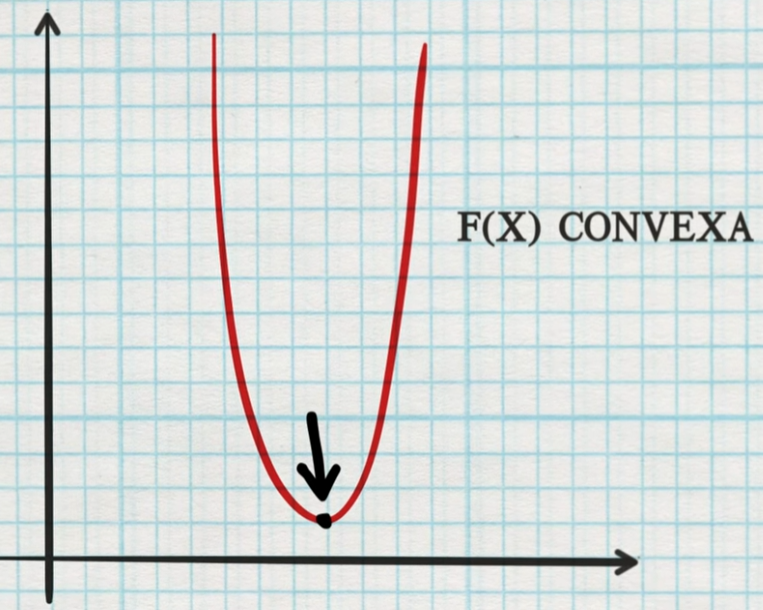

Por eso, intuitivamente, es fácil encontrar el mínimo local, además que acompañado de los dos parámetros sobre los cuales debemos encontrar la optimización, pareciera que nos enfrentamos a un problema "trivial"

Pero ahora... Qué sucede cuando nuestra función de coste + complejidad de parámetros, genera una función a optimizar de este estilo:

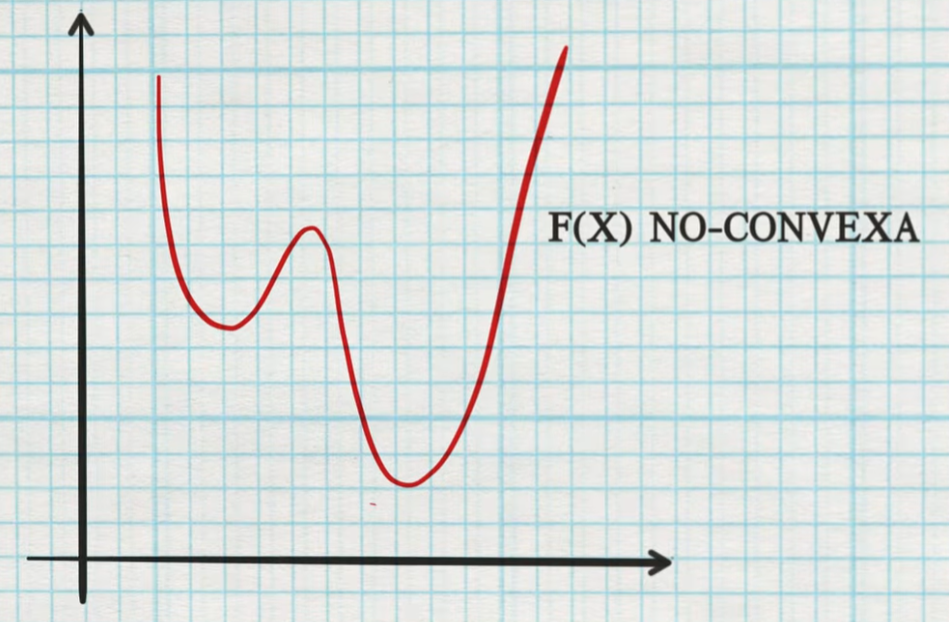

Es claro que nuestro problema cambia, podríamos estar cayendo en mínimos locales y no globales, incluso en puntos de silla, lo que generaría grandes problemas en la estimación del modelo.



## Idea intuitiva del gradiente descendiente

Vamos a plantearnos en una situación hipótetica, para entender este concepto.

Supongan que se encuentran en un lugar rodeado de montañas, con los ojos completamente vendados, sin acceso a un mapa o cualquier tipo de tecnología.

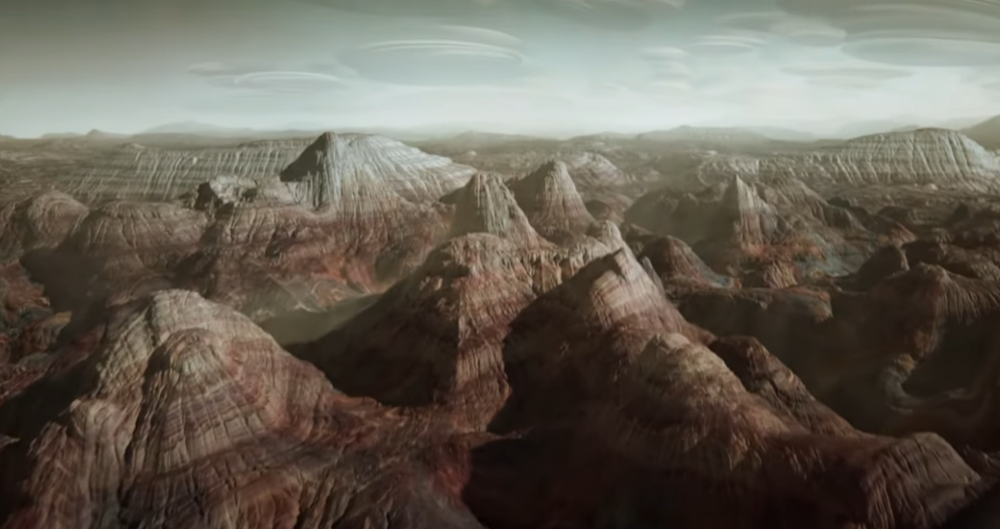

Desde el punto en que ustedes son abandonados en este lugar, el objetivo es llegar a la parte más baja de todo el terreno.

¿Cómo lo harían bajo las condiciones dadas?

## La solución intuitiva

El punto más bajo podría ser encontrado dando un paso a la vez, ustedes serían capaces de sentir el terreno debajo de sus pies y caminar en la dirección donde cada paso que den sientan que van en una pendiente negativa.

Ahora, la idea intuitiva se completa cuando se encuentran en una posición donde hay dos pendientes negativas, cuál de las dos tomar? La decisión en este caso es tomar el camino donde localicen la mayor pendiente negativa en la posición actual.

Una vez realizan el movimiento en esa dirección, vuelven a evaluar la pendiente y repiten el proceso hasta que encuentren el punto de convergencia

## Formulación matemática del descenso del gradiente

Supongan que esta es la función de coste:

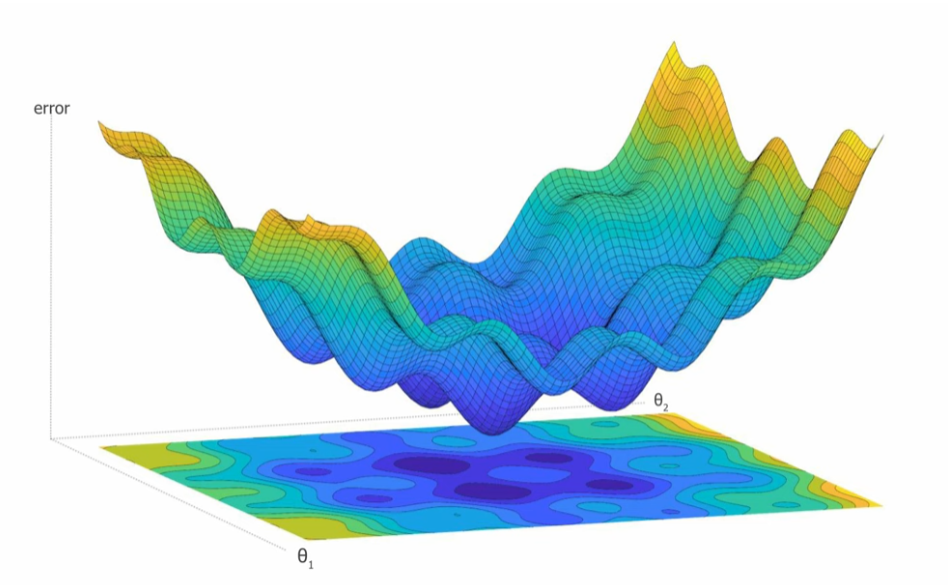

Es una función de coste con solamente dos parámetros $\theta_1$ y $\theta_2$. (Recuerden que en Machine Learning tenemos modelos con miles, incluso, millones de parámetros).

Para encontrar el mínimo de esta función de coste, partiendo de un punto aleatorio, deberán calcular el gradiente (vector de derivadas parciales), y encontrar la dirección donde la pendiente es máxima de forma negativa:

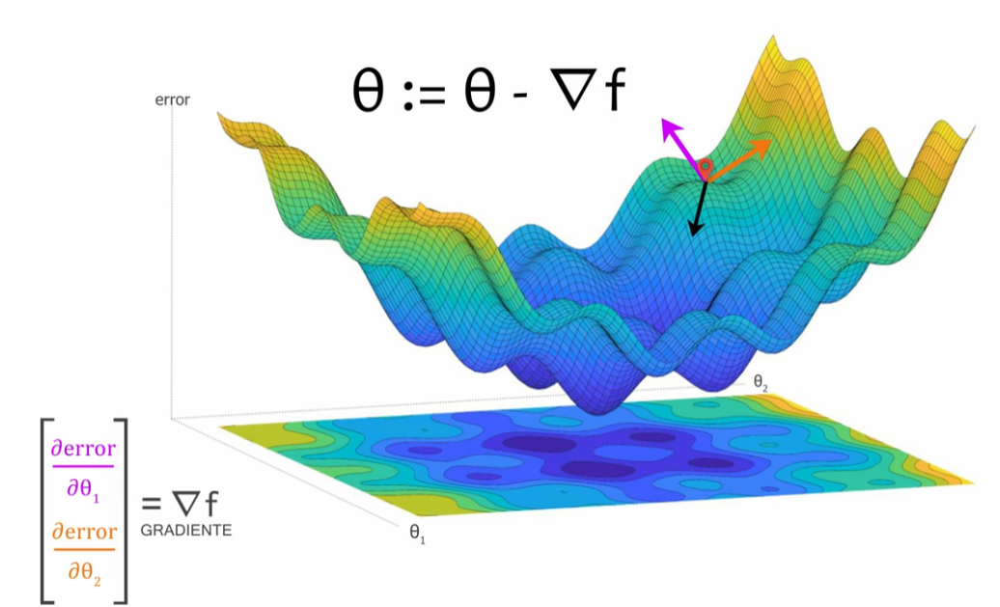

Lo que nos lleva a ir actualizando los parámetros del modelo a través de la siguiente fórmula:

$$\theta_{i+1} = \theta_i - \delta \nabla f$$

Donde $\delta$ hace referencia a que tan "grandes" serán los pasos que van a dar en cada iteración, a este parámetro se le conoce como **learning rate**, generalmente es un número entre 0.0001 y 0.1; y de este depende que tan rápido o que tan preciso puede llegar a ser el algoritmo.

Pueden acceder a algunas visualizaciones para entender más este proceso en la página web: https://www.benfrederickson.com/numerical-optimization/

Veamos ahora el gradiente descendente **en acción**, sobre superficies de pérdida que podemos rotar y recorrer época por época 👇

## 📉 El gradiente descendente, en 3D

Para poder graficar la función de pérdida usamos modelos con **solo dos parámetros**. Cada combinación de parámetros produce un error, y al graficar todos esos errores obtenemos una **superficie**. El punto más bajo de esa superficie corresponde al mejor modelo.

El gradiente descendente repite tres pasos:

1. Calcula el **gradiente**: la dirección en la que el error aumenta más rápido.
2. Mueve los parámetros en la **dirección contraria**, para que el error baje.
3. Repite. Cada repetición se llama **época**.

$$\text{nuevo valor} = \text{valor actual} - \eta \times \text{gradiente}$$

$\eta$ es el **learning rate**: controla el tamaño de cada paso.

### Cómo leer las figuras

| Panel | Qué muestra |
|---|---|
| Arriba a la izquierda | La función de pérdida en 3D (se puede rotar con el mouse) y el recorrido de los parámetros |
| Arriba a la derecha | La misma función vista desde arriba (curvas de nivel). La flecha indica la dirección del siguiente paso y la ⭐ marca el mínimo |
| Abajo a la izquierda | El modelo sobre los datos en esa época |
| Abajo a la derecha | El error en cada época |

👉 Mueve el slider **"Época"** o presiona **▶ Play**.

Veremos tres modelos:

1. Una **recta**.
2. Una **regresión logística** (clasificación).
3. Una **suma de dos árboles**.

In [135]:
# 🔧 Herramientas para dibujar las animaciones.
# No hace falta entender este código: solo ejecútalo una vez.

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

PALETA = ['#e4572e', '#1f9bd1', '#8e44ad', '#2ca02c']   # un color por trayectoria


def gradient_descent(grad_fn, theta0, lr, n_epochs):
    """Descenso de gradiente clásico: θ ← θ − η·∇L(θ). Devuelve la trayectoria (n_epochs+1, 2)."""
    theta = np.array(theta0, dtype=float)
    camino = [theta.copy()]
    for _ in range(n_epochs):
        theta = theta - lr * grad_fn(theta)
        camino.append(theta.copy())
    return np.array(camino)


def agregar_animacion(fig, dinamicas, posiciones, cuadros, prefijo='Época: ', titulo_fn=None, duracion=150):
    """Agrega a `fig` las trazas que cambian en cada cuadro, los frames, el slider y los botones Play/Pausa.

    dinamicas(k) -> lista de trazas del cuadro k;  posiciones -> (fila, col) de cada una de esas trazas.
    """
    n_estaticas = len(fig.data)
    for traza, (fila, col) in zip(dinamicas(cuadros[0]), posiciones):
        fig.add_trace(traza, row=fila, col=col)
    indices = list(range(n_estaticas, len(fig.data)))

    frames = []
    for k in cuadros:
        extra = dict(layout=go.Layout(title_text=titulo_fn(k))) if titulo_fn else {}
        frames.append(go.Frame(name=str(k), data=dinamicas(k), traces=indices, **extra))
    fig.frames = frames

    def paso(k):
        return dict(label=str(k), method='animate',
                    args=[[str(k)], dict(mode='immediate', frame=dict(duration=0, redraw=True),
                                         transition=dict(duration=0))])

    fig.update_layout(
        updatemenus=[dict(type='buttons', direction='left', showactive=False,
                          x=0, y=0, xanchor='left', yanchor='top', pad=dict(t=65, r=10),
                          buttons=[dict(label='▶ Play', method='animate',
                                        args=[None, dict(frame=dict(duration=duracion, redraw=True),
                                                         transition=dict(duration=0),
                                                         fromcurrent=True, mode='immediate')]),
                                   dict(label='⏸ Pausa', method='animate',
                                        args=[[None], dict(frame=dict(duration=0, redraw=False),
                                                           transition=dict(duration=0), mode='immediate')])])],
        sliders=[dict(active=0, x=0.16, len=0.84, y=0, yanchor='top', pad=dict(t=50),
                      currentvalue=dict(prefix=prefijo, font=dict(size=14)),
                      steps=[paso(k) for k in cuadros])])
    if titulo_fn:
        fig.update_layout(title_text=titulo_fn(cuadros[0]))
    return fig


def animate_descent(loss_fn, grad_fn, caminos, rango, datos, curva_modelo,
                    nombres_param=('θ₁', 'θ₂'), optimo=None, titulo='', rango_y_modelo=None, cada=1):
    """Figura interactiva del descenso sobre una pérdida de 2 parámetros.

    caminos: dict {nombre: trayectoria (n, 2)}  — permite comparar varios learning rates / métodos.
    rango:   ((θ₁_min, θ₁_max), (θ₂_min, θ₂_max)) de la malla.
    datos:   (x, y) para el panel del modelo;  curva_modelo(θ) -> (xs, ys).
    cada:    dibuja un cuadro cada `cada` épocas (para animaciones largas).
    """
    (a0, a1), (b0, b1) = rango
    p1, p2 = nombres_param
    nombres = list(caminos)
    n = max(len(c) for c in caminos.values())
    # trayectorias de igual longitud: si una es más corta, se queda quieta en su último punto
    caminos = {k: np.vstack([c, np.repeat(c[-1:], n - len(c), axis=0)]) for k, c in caminos.items()}

    with np.errstate(over='ignore', invalid='ignore'):
        perdidas = {k: np.array([loss_fn(t) for t in c]) for k, c in caminos.items()}
    perd_vis = {k: np.minimum(np.nan_to_num(v, nan=1e8, posinf=1e8), 1e8) for k, v in perdidas.items()}

    # superficie de pérdida sobre una malla de parámetros
    ta, tb = np.linspace(a0, a1, 70), np.linspace(b0, b1, 70)
    Z = np.array([[loss_fn(np.array([p, q])) for p in ta] for q in tb])

    # si un camino diverge, lo dibujamos "pegado" al borde de la gráfica
    visibles = {k: np.column_stack([np.clip(c[:, 0], a0, a1), np.clip(c[:, 1], b0, b1)])
                for k, c in caminos.items()}
    z_vis = {k: np.array([loss_fn(t) for t in c]) for k, c in visibles.items()}

    fig = make_subplots(rows=2, cols=2,
                        specs=[[{'type': 'scene'}, {'type': 'xy'}], [{'type': 'xy'}, {'type': 'xy'}]],
                        column_widths=[0.55, 0.45], row_heights=[0.62, 0.38],
                        vertical_spacing=0.09, horizontal_spacing=0.07,
                        subplot_titles=('Superficie de pérdida L', 'Curvas de nivel y dirección −∇L',
                                        'El modelo sobre los datos', 'Pérdida por época'))

    # ---------- trazas estáticas ----------
    fig.add_trace(go.Surface(x=ta, y=tb, z=Z, colorscale='Viridis', opacity=0.85, showscale=False,
                             contours=dict(z=dict(show=True, usecolormap=True, project_z=True)),
                             hovertemplate=f'{p1} = %{{x:.2f}}<br>{p2} = %{{y:.2f}}<br>L = %{{z:.3f}}<extra></extra>'),
                  row=1, col=1)
    fig.add_trace(go.Contour(x=ta, y=tb, z=np.log(Z), colorscale='Viridis', showscale=False, ncontours=25,
                             contours=dict(coloring='lines'), line=dict(width=1.2), hoverinfo='skip'),
                  row=1, col=2)
    fig.add_trace(go.Scatter(x=datos[0], y=datos[1], mode='markers', name='datos', showlegend=False,
                             marker=dict(color='#333', size=8, opacity=0.65)), row=2, col=1)
    if optimo is not None:
        z_opt = loss_fn(np.array(optimo, dtype=float))
        fig.add_trace(go.Scatter3d(x=[optimo[0]], y=[optimo[1]], z=[z_opt], mode='markers', showlegend=False,
                                   marker=dict(symbol='diamond', size=7, color='gold', line=dict(color='black', width=1))),
                      row=1, col=1)
        fig.add_trace(go.Scatter(x=[optimo[0]], y=[optimo[1]], mode='markers', name='mínimo exacto',
                                 marker=dict(symbol='star', size=18, color='gold', line=dict(color='black', width=1))),
                      row=1, col=2)
    for i, k in enumerate(nombres):
        fig.add_trace(go.Scatter(x=np.arange(n), y=perd_vis[k], mode='lines', legendgroup=k, showlegend=False,
                                 line=dict(color=PALETA[i % len(PALETA)], width=2)), row=2, col=2)

    # ---------- trazas que cambian en cada época ----------
    escala = np.array([a1 - a0, b1 - b0])

    def flecha(theta, col):
        """Segmento con punta de flecha en la dirección −∇L (dibujado con longitud fija)."""
        xs, ys = [None, None], [None, None]
        dentro = (a0 <= theta[0] <= a1) and (b0 <= theta[1] <= b1)
        if dentro:
            d = -grad_fn(theta) / escala                # dirección de −∇L vista en la pantalla
            if np.all(np.isfinite(d)) and np.linalg.norm(d) > 1e-12:
                fin = theta + 0.12 * d / np.linalg.norm(d) * escala
                xs, ys = [theta[0], fin[0]], [theta[1], fin[1]]
        return go.Scatter(x=xs, y=ys, mode='lines+markers', showlegend=False, hoverinfo='skip',
                          line=dict(color=col, width=2),
                          marker=dict(symbol='arrow', angleref='previous', size=[0, 14], color=col))

    def dinamicas(k):
        trazas = []
        for i, nombre in enumerate(nombres):
            col = PALETA[i % len(PALETA)]
            c, z = visibles[nombre][:k + 1], z_vis[nombre][:k + 1]
            xs, ys = curva_modelo(caminos[nombre][k])
            trazas += [
                go.Scatter3d(x=c[:, 0], y=c[:, 1], z=z, mode='lines+markers', legendgroup=nombre,
                             showlegend=False, hoverinfo='skip', line=dict(color=col, width=6),
                             marker=dict(size=[3] * k + [9], color=col)),
                go.Scatter(x=c[:, 0], y=c[:, 1], mode='lines+markers', name=nombre, legendgroup=nombre,
                           line=dict(color=col, width=2),
                           marker=dict(size=[5] * k + [13], color=col, line=dict(color='white', width=1))),
                flecha(caminos[nombre][k], col),
                go.Scatter(x=xs, y=ys, mode='lines', legendgroup=nombre, showlegend=False,
                           line=dict(color=col, width=3)),
                go.Scatter(x=[k], y=[perd_vis[nombre][k]], mode='markers', legendgroup=nombre, showlegend=False,
                           marker=dict(color=col, size=11, line=dict(color='black', width=1))),
            ]
        return trazas

    posiciones = [(1, 1), (1, 2), (1, 2), (2, 1), (2, 2)] * len(nombres)
    cuadros = list(range(0, n, cada))
    if cuadros[-1] != n - 1:
        cuadros.append(n - 1)

    def titulo_fn(k):
        resumen = '   '.join(f'{nm}: L = {perdidas[nm][k]:.4g}' for nm in nombres)
        return f'<b>{titulo}</b> · época {k}<br><sup>{resumen}</sup>'

    agregar_animacion(fig, dinamicas, posiciones, cuadros, prefijo='Época: ', titulo_fn=titulo_fn)

    # ---------- ejes y estilo ----------
    if rango_y_modelo is None:
        rango_y_modelo = (np.min(datos[1]) - 1, np.max(datos[1]) + 1)
    fig.update_layout(
        height=950, template='plotly_white', margin=dict(l=20, r=20, t=150, b=130),
        legend=dict(orientation='h', x=1, xanchor='right', y=1.045, yanchor='bottom'),
        scene=dict(xaxis=dict(title=p1, range=[a0, a1]), yaxis=dict(title=p2, range=[b0, b1]),
                   zaxis=dict(title='L', range=[Z.min() - 0.05 * (Z.max() - Z.min()), Z.max()]),
                   aspectmode='manual', aspectratio=dict(x=1, y=1, z=0.7),
                   camera=dict(eye=dict(x=1.5, y=-1.6, z=0.9))))
    fig.update_xaxes(title_text=p1, range=[a0, a1], row=1, col=2)
    fig.update_yaxes(title_text=p2, range=[b0, b1], row=1, col=2)
    fig.update_xaxes(title_text='x', row=2, col=1)
    fig.update_yaxes(title_text='y', range=list(rango_y_modelo), row=2, col=1)
    fig.update_xaxes(title_text='época', range=[-1, n], row=2, col=2)
    fig.update_yaxes(title_text='L (escala log)', type='log', row=2, col=2)
    return fig

### 1️⃣ Una recta

**Modelo:**

$$\hat y_i = m\,x_i + b$$

Los dos parámetros son la **pendiente** $m$ y el **intercepto** $b$.

**Función de pérdida: error cuadrático medio (MSE).** Es el promedio de los errores al cuadrado sobre las $n$ observaciones:

$$L(m, b) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - \hat{y}\big)^2$$

$$L(m, b) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - (m\,x_i + b)\big)^2$$

**Gradientes (fórmula cerrada).** Se obtienen derivando $L$ respecto a cada parámetro con la **regla de la cadena**: primero se deriva el cuadrado (derivada externa) y luego se multiplica por la derivada de lo que está dentro del paréntesis (derivada interna).

Las derivadas internas son:

$$\frac{\partial}{\partial m}\big(y_i - (m\,x_i + b)\big) = -x_i \qquad\qquad \frac{\partial}{\partial b}\big(y_i - (m\,x_i + b)\big) = -1$$

Entonces, para $m$:

$$\frac{\partial L}{\partial m} = \frac{1}{n}\sum_{i=1}^{n} \underbrace{2\big(y_i - \hat y_i\big)}_{\text{derivada externa}}\cdot\underbrace{(-x_i)}_{\text{derivada interna}} = -\frac{2}{n}\sum_{i=1}^{n} x_i\,\big(y_i - \hat y_i\big)$$

Y para $b$:

$$\frac{\partial L}{\partial b} = \frac{1}{n}\sum_{i=1}^{n} \underbrace{2\big(y_i - \hat y_i\big)}_{\text{derivada externa}}\cdot\underbrace{(-1)}_{\text{derivada interna}} = -\frac{2}{n}\sum_{i=1}^{n} \big(y_i - \hat y_i\big)$$

Los dos gradientes dependen del **residuo** $y_i - \hat y_i$ (dato real − predicción):

- Si la recta queda **por debajo** de los puntos, los residuos son positivos y el gradiente la sube.
- Si queda **por encima**, los residuos son negativos y el gradiente la baja.

**Actualización en cada época:**

$$m \leftarrow m - \eta\,\frac{\partial L}{\partial m} \qquad\qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

En este caso conocemos la solución exacta (⭐), así que podemos comprobar que el gradiente descendente llega al mismo resultado.

In [136]:
X = np.array([2.0, 5.0, 3.0, 1.0, 4.0, 6.0, 5.0, 3.0, 4.0, 2.0, 1.0, 6.0])
y = np.array([2.0, 4.0, 5.0, 1.0, 3.0, 6.0, 5.0, 4.0, 2.0, 3.0, 1.0, 6.0])


def mse_recta(theta):
    m, b = theta
    return np.mean((y - (m * X + b)) ** 2)


def grad_mse_recta(theta):
    m, b = theta
    residuo = y - (m * X + b)
    return np.array([-2 * np.mean(X * residuo),    # ∂L/∂m
                     -2 * np.mean(residuo)])       # ∂L/∂b


def curva_recta(theta):
    xs = np.linspace(0, 7, 50)
    return xs, theta[0] * xs + theta[1]


m_ols, b_ols = np.polyfit(X, y, 1)                # solución exacta (OLS), solo para comparar
camino = gradient_descent(grad_mse_recta, theta0=[-1.5, 3.8], lr=0.05, n_epochs=200)

print(f'OLS (exacto):        m = {m_ols:.3f}, b = {b_ols:.3f}   L = {mse_recta([m_ols, b_ols]):.4f}')
print(f'GD tras 200 épocas:  m = {camino[-1, 0]:.3f}, b = {camino[-1, 1]:.3f}   L = {mse_recta(camino[-1]):.4f}')

fig = animate_descent(mse_recta, grad_mse_recta, {'η = 0.05': camino},
                      rango=((-1.5, 2.5), (-2.0, 6.0)), datos=(X, y), curva_modelo=curva_recta,
                      nombres_param=('m (pendiente)', 'b (intercepto)'), optimo=(m_ols, b_ols),
                      titulo='Recta + MSE', rango_y_modelo=(-1, 8), cada=2)
fig.show()

OLS (exacto):        m = 0.829, b = 0.600   L = 0.9143
GD tras 200 épocas:  m = 0.808, b = 0.689   L = 0.9158


**¿Qué vemos?**

- Los primeros pasos son **grandes**, porque el gradiente es grande. Cerca del mínimo el gradiente se hace pequeño y los pasos también.
- La superficie tiene **un solo mínimo**, así que el algoritmo siempre llega a él.
- La superficie es **alargada**: el algoritmo baja rápido en una dirección y avanza despacio en la otra.

#### ⚙️ Efecto del learning rate

Corremos el algoritmo tres veces desde el mismo punto, cambiando solo $\eta$:

- **η = 0.005 (muy pequeño)**: el error baja, pero muy despacio.
- **η = 0.05 (adecuado)**: llega rápido al mínimo.
- **η = 0.1 (muy grande)**: los pasos se pasan del mínimo, cada vez más lejos, y el error **aumenta**. A esto se le llama **divergir**.

> 💡 **Para recordar:** si el learning rate es muy pequeño, el entrenamiento es lento; si es muy grande, el modelo no converge.

In [137]:
caminos = {f'η = {lr}': gradient_descent(grad_mse_recta, [-1.5, 4], lr, n_epochs=60)
           for lr in [0.06, 0.05, 0.005]}
for nombre, c in caminos.items():
    print(f'{nombre:>10}:  L(época 0) = {mse_recta(c[0]):.3f}   →   L(época 60) = {mse_recta(c[-1]):,.3f}')

fig = animate_descent(mse_recta, grad_mse_recta, caminos,
                      rango=((-1.5, 2.5), (-2.0, 6.0)), datos=(X, y), curva_modelo=curva_recta,
                      nombres_param=('m (pendiente)', 'b (intercepto)'), optimo=(m_ols, b_ols),
                      titulo='Comparando learning rates', rango_y_modelo=(-1, 8))
fig.show()

  η = 0.06:  L(época 0) = 39.292   →   L(época 60) = 1.104
  η = 0.05:  L(época 0) = 39.292   →   L(época 60) = 1.210
 η = 0.005:  L(época 0) = 39.292   →   L(época 60) = 3.076


### 2️⃣ Regresión logística (clasificación)

Ahora el modelo predice **probabilidades**, como en el problema de churn. Las clases son $y_i \in \{0, 1\}$.

**Modelo:**

$$\hat p_i = \sigma(w\,x_i + b) = \frac{1}{1 + e^{-(w\,x_i + b)}}$$

Los parámetros son $w$ (qué tan rápido cambia la curva de 0 a 1) y $b$ (dónde está el punto de cambio).

**Función de pérdida: log-loss (entropía cruzada binaria).** Penaliza mucho asignar una probabilidad alta a la clase equivocada:

$$L(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[\,y_i \log \hat p_i + (1 - y_i)\log\big(1 - \hat p_i\big)\Big]$$

- Si $y_i = 1$, solo cuenta $-\log \hat p_i$: la pérdida es pequeña cuando $\hat p_i$ se acerca a 1.
- Si $y_i = 0$, solo cuenta $-\log(1 - \hat p_i)$: la pérdida es pequeña cuando $\hat p_i$ se acerca a 0.

**Gradientes (fórmula cerrada).** Aquí la regla de la cadena tiene tres eslabones. Llamemos $z_i = w\,x_i + b$ y $\ell_i$ a la pérdida de la observación $i$:

$$\ell_i = -\Big[\,y_i \log \hat p_i + (1 - y_i)\log\big(1 - \hat p_i\big)\Big], \qquad \hat p_i = \sigma(z_i), \qquad z_i = w\,x_i + b$$

$$\frac{\partial \ell_i}{\partial w} = \frac{\partial \ell_i}{\partial \hat p_i}\cdot\frac{\partial \hat p_i}{\partial z_i}\cdot\frac{\partial z_i}{\partial w}$$

Cada eslabón por separado:

$$\frac{\partial \ell_i}{\partial \hat p_i} = -\frac{y_i}{\hat p_i} + \frac{1 - y_i}{1 - \hat p_i} = \frac{\hat p_i - y_i}{\hat p_i\,(1 - \hat p_i)}$$

$$\frac{\partial \hat p_i}{\partial z_i} = \sigma(z_i)\big(1 - \sigma(z_i)\big) = \hat p_i\,(1 - \hat p_i)$$

$$\frac{\partial z_i}{\partial w} = x_i \qquad\qquad \frac{\partial z_i}{\partial b} = 1$$

Al multiplicar, el término $\hat p_i\,(1 - \hat p_i)$ se cancela:

$$\frac{\partial \ell_i}{\partial w} = \frac{\hat p_i - y_i}{\hat p_i\,(1 - \hat p_i)}\cdot\hat p_i\,(1 - \hat p_i)\cdot x_i = \big(\hat p_i - y_i\big)\,x_i$$

Promediando sobre las $n$ observaciones:

$$\frac{\partial L}{\partial w} = \frac{1}{n}\sum_{i=1}^{n} \big(\hat p_i - y_i\big)\,x_i$$

$$\frac{\partial L}{\partial b} = \frac{1}{n}\sum_{i=1}^{n} \big(\hat p_i - y_i\big)$$

(para $b$ es igual, pero el último eslabón vale $1$ en vez de $x_i$).

En ambos gradientes aparece el error de cada observación:

$$\hat p_i - y_i = \text{probabilidad predicha} - \text{clase real}$$

🔑 **XGBoost usa exactamente esta cantidad** en los problemas de clasificación.

**Actualización en cada época:**

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w} \qquad\qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

In [138]:
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(3)
x_log = np.r_[rng.normal(-1, 1, 25), rng.normal(1, 1, 25)]
y_log = np.r_[np.zeros(25), np.ones(25)]


def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def logloss(theta):
    w, b = theta
    p = np.clip(sigmoide(w * x_log + b), 1e-12, 1 - 1e-12)
    return -np.mean(y_log * np.log(p) + (1 - y_log) * np.log(1 - p))


def grad_logloss(theta):
    w, b = theta
    p = sigmoide(w * x_log + b)
    return np.array([np.mean((p - y_log) * x_log),    # ∂L/∂w
                     np.mean(p - y_log)])             # ∂L/∂b


def curva_sigmoide(theta):
    xs = np.linspace(-4, 4, 100)
    return xs, sigmoide(theta[0] * xs + theta[1])


theta0 = [-2.0, 2.0]
camino_gd = gradient_descent(grad_logloss, theta0, lr=1.0, n_epochs=40)

ref = LogisticRegression(C=np.inf).fit(x_log.reshape(-1, 1), y_log)   # sin regularización
w_opt, b_opt = ref.coef_[0, 0], ref.intercept_[0]
print(f'sklearn (exacto):  w = {w_opt:.3f}, b = {b_opt:.3f}')
print(f'GD, 40 épocas:     w = {camino_gd[-1, 0]:.3f}, b = {camino_gd[-1, 1]:.3f}')

fig = animate_descent(logloss, grad_logloss,
                      {'Gradiente descendente (η = 1)': camino_gd},
                      rango=((-3.0, 4.0), (-3.0, 3.0)), datos=(x_log, y_log), curva_modelo=curva_sigmoide,
                      nombres_param=('w', 'b'), optimo=(w_opt, b_opt),
                      titulo='Regresión logística + log-loss', rango_y_modelo=(-0.1, 1.1))
fig.show()

sklearn (exacto):  w = 1.505, b = -0.042
GD, 40 épocas:     w = 1.505, b = -0.035


**¿Qué vemos?**

- El gradiente descendente llega a los mismos valores de $w$ y $b$ que calcula sklearn.
- A medida que avanzan las épocas, la curva se ajusta a los datos: probabilidades bajas para la clase 0 y altas para la clase 1.

### 3️⃣ Una suma de dos árboles

Ahora el modelo está hecho de **árboles**. Con los 12 puntos del ejemplo 1:

1. El árbol 1 ($h_1$) se entrena sobre $y$.
2. El árbol 2 ($h_2$) se entrena sobre los **residuos** del árbol 1, es decir, sobre lo que el árbol 1 no logró predecir.

Los dos árboles quedan **fijos**. Lo que aprendemos con gradiente descendente es el **peso de cada árbol**, $a$ y $b$.

**Modelo:**

$$F(x_i) = a\,h_1(x_i) + b\,h_2(x_i)$$

**Función de pérdida: error cuadrático medio (MSE).**

$$L(a, b) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - F(x_i)\big)^2 = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - a\,h_1(x_i) - b\,h_2(x_i)\big)^2$$

**Gradientes (fórmula cerrada).** Igual que en el ejemplo 1, usamos la regla de la cadena. Las derivadas internas son:

$$\frac{\partial}{\partial a}\big(y_i - a\,h_1(x_i) - b\,h_2(x_i)\big) = -h_1(x_i) \qquad\qquad \frac{\partial}{\partial b}\big(y_i - a\,h_1(x_i) - b\,h_2(x_i)\big) = -h_2(x_i)$$

Entonces:

$$\frac{\partial L}{\partial a} = \frac{1}{n}\sum_{i=1}^{n} \underbrace{2\big(y_i - F(x_i)\big)}_{\text{derivada externa}}\cdot\underbrace{\big(-h_1(x_i)\big)}_{\text{derivada interna}} = -\frac{2}{n}\sum_{i=1}^{n} h_1(x_i)\,\big(y_i - F(x_i)\big)$$

$$\frac{\partial L}{\partial b} = \frac{1}{n}\sum_{i=1}^{n} \underbrace{2\big(y_i - F(x_i)\big)}_{\text{derivada externa}}\cdot\underbrace{\big(-h_2(x_i)\big)}_{\text{derivada interna}} = -\frac{2}{n}\sum_{i=1}^{n} h_2(x_i)\,\big(y_i - F(x_i)\big)$$

Son las mismas fórmulas del ejemplo 1, cambiando $x_i$ por la predicción de cada árbol.

**Actualización en cada época:**

$$a \leftarrow a - \eta\,\frac{\partial L}{\partial a} \qquad\qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

Como el árbol 2 corrige los errores del árbol 1, esperamos que los pesos óptimos sean cercanos a $a = 1$ y $b = 1$.

In [139]:
from sklearn.tree import DecisionTreeRegressor

X_col = X.reshape(-1, 1)
h1 = DecisionTreeRegressor(max_depth=1).fit(X_col, y)
h2 = DecisionTreeRegressor(max_depth=1).fit(X_col, y - h1.predict(X_col))    # h2 aprende el residuo de h1
H1, H2 = h1.predict(X_col), h2.predict(X_col)
print(f'h1 corta en x = {h1.tree_.threshold[0]:.1f}    |    h2 corta en x = {h2.tree_.threshold[0]:.1f}')


def mse_arboles(theta):
    a, b = theta
    return np.mean((y - (a * H1 + b * H2)) ** 2)


def grad_mse_arboles(theta):
    a, b = theta
    residuo = y - (a * H1 + b * H2)
    return np.array([-2 * np.mean(H1 * residuo),    # ∂L/∂a
                     -2 * np.mean(H2 * residuo)])   # ∂L/∂b


def curva_arboles(theta):
    xs = np.linspace(0, 7, 400).reshape(-1, 1)
    return xs.ravel(), theta[0] * h1.predict(xs) + theta[1] * h2.predict(xs)


a_opt, b_opt_arb = np.linalg.lstsq(np.column_stack([H1, H2]), y, rcond=None)[0]
camino = gradient_descent(grad_mse_arboles, theta0=[-1, -0.25], lr=0.05, n_epochs=80)
print(f'Óptimo exacto:   a = {a_opt:.3f}, b = {b_opt_arb:.3f}')
print(f'GD, 80 épocas:   a = {camino[-1, 0]:.3f}, b = {camino[-1, 1]:.3f}')

fig = animate_descent(mse_arboles, grad_mse_arboles, {'η = 0.05': camino},
                      rango=((-1.0, 2.0), (-0.5, 3.0)), datos=(X, y), curva_modelo=curva_arboles,
                      nombres_param=('a (peso de h₁)', 'b (peso de h₂)'), optimo=(a_opt, b_opt_arb),
                      titulo='Ensamble de 2 árboles + MSE', rango_y_modelo=(-1, 8))
fig.show()

h1 corta en x = 2.5    |    h2 corta en x = 5.5
Óptimo exacto:   a = 0.979, b = 1.011
GD, 80 épocas:   a = 0.979, b = 0.995


**¿Qué vemos?**

- El modelo tiene forma **escalonada**, porque es una suma de árboles.
- El mínimo está, efectivamente, cerca de $(1, 1)$.

### Conexión con Gradient Boosting

En este ejemplo los árboles ya estaban definidos y el gradiente solo ajustó sus pesos. **Gradient Boosting** hace algo distinto:

> En lugar de ajustar pesos, **agrega árboles nuevos**. Cada árbol nuevo se entrena sobre los **errores que todavía quedan**.

Entrenar el árbol 2 sobre los residuos del árbol 1, como hicimos aquí, es exactamente un paso de Gradient Boosting.


---

## 2. 🌳 Weak Learner

En gradient boosting normalmente se usan **árboles de decisión** como *weak learners*.

Más específicamente, se usan **árboles de regresión** (que devuelven valores reales) y cuya salida se puede **sumar** a las salidas de los árboles anteriores. De esta forma los modelos siguientes pueden “corregir” los **residuales** de las predicciones anteriores 🔁.

- Los árboles se construyen de forma **greedy**, eligiendo los mejores puntos de corte según medidas como **Gini** o minimizando la pérdida.
- Al inicio (como en AdaBoost) se usaban árboles muy pequeños con una sola división (**decision stump**).
- En gradient boosting se suelen usar árboles un poco más profundos, por ejemplo de **4 a 8 niveles** 🌲.

Es común **restringir** a los weak learners: máximo de niveles, de nodos, de hojas, etc. Esto garantiza que sigan siendo **débiles** (no sobreajusten), pero que se puedan construir de forma greedy ✅.

---

## 3. ➕ Modelo aditivo

Los árboles se van **agregando uno a la vez** y los árboles que ya están en el modelo **no se modifican**.

Se usa un procedimiento de **descenso de gradiente** para minimizar la pérdida al agregar nuevos árboles 🧗.

Normalmente, el descenso de gradiente se usa para minimizar parámetros (por ejemplo los pesos de una red neuronal o los coeficientes de una regresión). Aquí la idea es similar, pero en lugar de parámetros tenemos **modelos débiles** (árboles).

1. Calculamos la **pérdida** del modelo actual.
2. Vemos en qué dirección debemos movernos para reducir esa pérdida (el **gradiente**).
3. Entrenamos un árbol **para aproximar ese gradiente** o los residuales.
4. Agregamos ese árbol al conjunto de árboles existente.

A esto se le llama **descenso de gradiente funcional** o **gradient descent en el espacio de funciones** 📐.

> “One way to produce a weighted combination of classifiers which optimizes the cost is by gradient descent in function space.”
>
> — *Boosting Algorithms as Gradient Descent in Function Space*, 1999 📄

El output del nuevo árbol se **suma** al output de la secuencia previa de árboles para **corregir o mejorar** la salida final del modelo ✅.

El proceso puede:

- usar un **número fijo de árboles**,
- detenerse cuando la pérdida llega a un nivel aceptable,
- o cuando **ya no mejora** en un conjunto de validación externo 🛑.

---


---

# 🔗 Gradient Boosting: cada árbol corrige los errores del anterior

El algoritmo es:

1. Empezar con una predicción simple (por ejemplo, el promedio de $y$).
2. Calcular los **residuos**: dato real − predicción actual.
3. Entrenar un **árbol pequeño** para predecir esos residuos.
4. Sumar ese árbol a la predicción, multiplicado por el learning rate $\eta$.
5. Repetir desde el paso 2.

$$\text{predicción nueva} = \text{predicción anterior} + \eta \times \text{árbol nuevo}$$

### ¿Por qué se llama "Gradient" Boosting?

En el ejemplo de abajo usamos como **función de pérdida el error cuadrático** de cada observación. Se multiplica por $\frac{1}{2}$ solo para que la derivada quede más limpia:

$$L\big(y_i, F(x_i)\big) = \frac{1}{2}\big(y_i - F(x_i)\big)^2$$

Su **gradiente** respecto a la predicción $F(x_i)$ se obtiene con la regla de la cadena. La derivada interna es:

$$\frac{\partial}{\partial F(x_i)}\big(y_i - F(x_i)\big) = -1$$

porque $y_i$ es una constante. Entonces:

$$\frac{\partial L}{\partial F(x_i)} = \underbrace{\frac{1}{2}\cdot 2\,\big(y_i - F(x_i)\big)}_{\text{derivada externa}}\cdot\underbrace{(-1)}_{\text{derivada interna}} = -\big(y_i - F(x_i)\big)$$

El $2$ que baja del cuadrado se cancela con el $\frac{1}{2}$, y el signo menos viene de la derivada interna.

Por lo tanto, el **gradiente negativo es exactamente el residuo**:

$$-\frac{\partial L}{\partial F(x_i)} = y_i - F(x_i) = \text{residuo}_i$$

Es decir, cada árbol aprende la dirección en la que hay que mover las predicciones para reducir el error, igual que en el gradiente descendente. La diferencia es que aquí el paso lo da un árbol, no un cambio en los parámetros:

$$F_m(x) = F_{m-1}(x) + \eta\,h_m(x), \qquad h_m \text{ entrenado sobre } \; y_i - F_{m-1}(x_i)$$

Veámoslo árbol por árbol 👇

In [140]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(42)
x_gb = np.sort(rng.uniform(0, 10, 80))
y_gb = np.sin(x_gb) + 0.3 * rng.normal(size=80)
x_val = rng.uniform(0, 10, 300)                     # datos de validación (misma distribución)
y_val = np.sin(x_val) + 0.3 * rng.normal(size=300)
x_grid = np.linspace(0, 10, 400)


def gradient_boosting_mse(x, y, n_arboles, eta, max_depth=2):
    """Gradient Boosting desde cero con pérdida ½(y − F)². Guarda la historia para animarla."""
    xc, xg, xv = x.reshape(-1, 1), x_grid.reshape(-1, 1), x_val.reshape(-1, 1)
    F, F_grid, F_val = (np.full(len(v), y.mean()) for v in (x, x_grid, x_val))   # F_0 = promedio
    hist = dict(F=[F_grid.copy()], residuo=[y - F], arbol=[np.zeros_like(x_grid)],
                mse=[np.mean((y - F) ** 2)], mse_val=[np.mean((y_val - F_val) ** 2)])
    for m in range(n_arboles):
        residuo = y - F                                      # = −gradiente de ½(y − F)²
        arbol = DecisionTreeRegressor(max_depth=max_depth).fit(xc, residuo)
        F = F + eta * arbol.predict(xc)                      # el paso, ahora en el espacio de funciones
        F_grid = F_grid + eta * arbol.predict(xg)
        F_val = F_val + eta * arbol.predict(xv)
        hist['F'].append(F_grid.copy())
        hist['residuo'].append(residuo)
        hist['arbol'].append(arbol.predict(xg))
        hist['mse'].append(np.mean((y - F) ** 2))
        hist['mse_val'].append(np.mean((y_val - F_val) ** 2))
    return hist


hist = gradient_boosting_mse(x_gb, y_gb, n_arboles=40, eta=0.3)
print(f'MSE de entrenamiento:  F₀ (promedio) = {hist["mse"][0]:.3f}   →   con 40 árboles = {hist["mse"][-1]:.3f}')

MSE de entrenamiento:  F₀ (promedio) = 0.547   →   con 40 árboles = 0.013


In [141]:
def animar_boosting(hist, eta):
    M = len(hist['F']) - 1
    fig = make_subplots(rows=1, cols=3, column_widths=[0.38, 0.38, 0.24], horizontal_spacing=0.06,
                        subplot_titles=('Modelo Fₘ(x) sobre los datos',
                                        'Pseudo-residuos (−gradiente) y el árbol hₘ',
                                        'MSE de entrenamiento'))
    # estáticas
    fig.add_trace(go.Scatter(x=x_gb, y=y_gb, mode='markers', name='datos',
                             marker=dict(color='#333', size=6, opacity=0.55)), row=1, col=1)
    fig.add_trace(go.Scatter(x=x_grid, y=np.sin(x_grid), mode='lines', name='función real sin(x)',
                             line=dict(color='#999', dash='dot')), row=1, col=1)
    fig.add_trace(go.Scatter(x=np.arange(M + 1), y=hist['mse'], mode='lines', showlegend=False,
                             line=dict(color=PALETA[0], width=2)), row=1, col=3)

    def dinamicas(m):
        return [
            go.Scatter(x=x_grid, y=hist['F'][m], mode='lines', name='Fₘ(x)', line=dict(color=PALETA[0], width=3)),
            go.Scatter(x=x_gb, y=hist['residuo'][m], mode='markers', name='residuo  yᵢ − Fₘ₋₁(xᵢ)',
                       marker=dict(color=PALETA[1], size=6)),
            go.Scatter(x=x_grid, y=hist['arbol'][m], mode='lines', name='árbol hₘ(x)',
                       line=dict(color=PALETA[2], width=3)),
            go.Scatter(x=[m], y=[hist['mse'][m]], mode='markers', showlegend=False,
                       marker=dict(color=PALETA[0], size=11, line=dict(color='black', width=1))),
        ]

    agregar_animacion(fig, dinamicas, [(1, 1), (1, 2), (1, 2), (1, 3)], list(range(M + 1)),
                      prefijo='Árbol m = ', duracion=350,
                      titulo_fn=lambda m: f'<b>Gradient Boosting desde cero</b> (η = {eta}) · árbol {m} · '
                                          f'MSE = {hist["mse"][m]:.3f}')
    fig.update_layout(height=560, template='plotly_white', margin=dict(l=20, r=20, t=130, b=120),
                      legend=dict(orientation='h', x=1, xanchor='right', y=1.09, yanchor='bottom'))
    fig.update_yaxes(range=[-2.2, 2.2], row=1, col=1)
    fig.update_yaxes(range=[-2.2, 2.2], row=1, col=2)
    fig.update_xaxes(title_text='x', row=1, col=1)
    fig.update_xaxes(title_text='x', row=1, col=2)
    fig.update_xaxes(title_text='número de árboles', row=1, col=3)
    return fig


animar_boosting(hist, eta=0.3).show()

**¿Qué vemos?**

- **Panel central**: cada árbol nuevo (línea morada) intenta predecir los **residuos** (puntos azules).
- Al principio los residuos tienen un patrón claro, que los árboles van capturando. Después de muchos árboles, los residuos parecen **ruido**: ya no queda patrón por aprender.

#### Efecto del learning rate en Gradient Boosting

Repetimos el proceso con tres valores de $\eta$ y medimos el error también en **datos de validación**, que el modelo no usa para entrenar.

In [142]:
etas = [1.0, 0.3, 0.05]
hists = {eta: gradient_boosting_mse(x_gb, y_gb, n_arboles=100, eta=eta) for eta in etas}
for eta, h in hists.items():
    mejor = int(np.argmin(h['mse_val']))
    print(f'η = {eta:<5} MSE val. mínimo = {h["mse_val"][mejor]:.3f} (con {mejor:>3} árboles)   '
          f'MSE val. con 100 árboles = {h["mse_val"][-1]:.3f}')

fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.08,
                    subplot_titles=('Fₘ(x) para cada η', 'MSE: entrenamiento (punteado) y validación (sólido)'))
fig.add_trace(go.Scatter(x=x_gb, y=y_gb, mode='markers', name='datos', marker=dict(color='#333', size=6, opacity=0.5)),
              row=1, col=1)
for i, (eta, h) in enumerate(hists.items()):
    col = PALETA[i]
    fig.add_trace(go.Scatter(x=np.arange(101), y=h['mse'], mode='lines', legendgroup=str(eta), showlegend=False,
                             line=dict(color=col, dash='dot')), row=1, col=2)
    fig.add_trace(go.Scatter(x=np.arange(101), y=h['mse_val'], mode='lines', legendgroup=str(eta), showlegend=False,
                             line=dict(color=col, width=2.5)), row=1, col=2)


def dinamicas(m):
    trazas = []
    for i, (eta, h) in enumerate(hists.items()):
        trazas.append(go.Scatter(x=x_grid, y=h['F'][m], mode='lines', name=f'η = {eta}', legendgroup=str(eta),
                                 line=dict(color=PALETA[i], width=3)))
        trazas.append(go.Scatter(x=[m], y=[h['mse_val'][m]], mode='markers', legendgroup=str(eta), showlegend=False,
                                 marker=dict(color=PALETA[i], size=10, line=dict(color='black', width=1))))
    return trazas


agregar_animacion(fig, dinamicas, [(1, 1), (1, 2)] * len(etas), list(range(101)), prefijo='Árbol m = ', duracion=120,
                  titulo_fn=lambda m: f'<b>Efecto del learning rate</b> · árbol {m}')
fig.update_layout(height=560, template='plotly_white', margin=dict(l=20, r=20, t=130, b=110),
                  legend=dict(orientation='h', x=1, xanchor='right', y=1.09, yanchor='bottom'))
fig.update_yaxes(range=[-2.2, 2.2], row=1, col=1)
fig.update_yaxes(range=[0, 0.35], title_text='MSE', row=1, col=2)
fig.update_xaxes(title_text='x', row=1, col=1)
fig.update_xaxes(title_text='número de árboles', row=1, col=2)
fig.show()

η = 1.0   MSE val. mínimo = 0.155 (con   3 árboles)   MSE val. con 100 árboles = 0.185
η = 0.3   MSE val. mínimo = 0.135 (con  13 árboles)   MSE val. con 100 árboles = 0.171
η = 0.05  MSE val. mínimo = 0.142 (con  79 árboles)   MSE val. con 100 árboles = 0.142


**¿Qué vemos?**

- **η = 1**: el error de entrenamiento baja muy rápido, pero el de validación empieza a subir pronto. El modelo está aprendiendo el ruido: **sobreajuste**.
- **η = 0.05**: aprende más despacio, pero termina con el menor error de validación.

> 💡 **Para recordar:** con un learning rate pequeño se necesitan más árboles, pero el modelo generaliza mejor. Por eso `learning_rate` y `n_estimators` se ajustan **juntos**.

Ahora veamos la versión de Scikit-learn:

In [143]:
from sklearn.ensemble import GradientBoostingClassifier

clf = GradientBoostingClassifier()
clf

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [144]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
metrics.f1_score(y_pred, y_test.values), metrics.accuracy_score(y_pred, y_test.values)

(0.46445497630331756, 0.8972727272727272)

# 🛠️ Mejoras al Gradient Boosting básico

El **gradient boosting** es un algoritmo codicioso (*greedy*) y puede **sobreajustar** el conjunto de entrenamiento muy rápido.

Puede beneficiarse de **métodos de regularización** que penalizan distintas partes del algoritmo y, en general, mejoran su desempeño reduciendo el sobreajuste.

En esta sección veremos **4 mejoras** al gradient boosting básico:

1. 🌳 Restricciones a los árboles  
2. 🐢 Tasa de aprendizaje (learning rate)  
3. 🎯 Muestreo aleatorio (stochastic gradient boosting)  
4. 🧰 Aprendizaje penalizado

---

## 1. 🌳 Restricciones a los árboles

Es importante que los *weak learners* (los árboles débiles) **tengan capacidad predictiva**, pero que **sigan siendo débiles**.

Hay varias formas de **restringir** los árboles.

Una buena regla general es: **entre más restringida esté la construcción de cada árbol, más árboles necesitarás en el modelo**; y al revés: **si los árboles son menos restringidos, necesitarás menos árboles**.

Algunas restricciones que se pueden imponer a la construcción de los árboles de decisión:

- **Número de árboles**: en general, agregar más árboles hace que el modelo tarde más en sobreajustar. La recomendación es seguir agregando árboles hasta que no se vea más mejora. ✅
- **Profundidad del árbol**: árboles más profundos son más complejos; se prefieren árboles más bajos. Usualmente se obtienen buenos resultados con **4 a 8 niveles**. 📏
- **Número de nodos u hojas**: similar a la profundidad, esto limita el tamaño del árbol, pero sin exigir que sea simétrico.
- **Número mínimo de observaciones por partición**: impone un tamaño mínimo de datos en un nodo antes de permitir una división. 📊
- **Mejora mínima en la función de pérdida**: exige una mejora mínima para aceptar un split en el árbol.

---

## 2. 🐢 Tasa de aprendizaje (learning rate)

Las predicciones de cada árbol se **van sumando secuencialmente**.

La contribución de cada árbol a esa suma se puede **ponderar** para **ralentizar el aprendizaje** del algoritmo. A esta ponderación se le conoce como **tasa de aprendizaje** (*learning rate*).

Cada actualización se escala por el valor del **parámetro de tasa de aprendizaje** \(v\).

> “Greedy Function Approximation: A Gradient Boosting Machine” [PDF], 1999

El efecto de esto es que el **aprendizaje se hace más lento**, y por lo tanto se requieren **más árboles** en el modelo, lo cual **toma más tiempo de entrenamiento**, pero ofrece una **mejor combinación** entre número de árboles y tasa de aprendizaje.

> “Decreasing the value of v [the learning rate] increases the best value for M [the number of trees].”
>
> — “Greedy Function Approximation: A Gradient Boosting Machine” [PDF], 1999

Es común usar valores pequeños en el rango **0.1 a 0.3**, e incluso menores a **0.1**.

Igual que en el gradiente descendente, la **tasa de aprendizaje reduce la influencia de cada árbol individual** y deja espacio para que los árboles futuros mejoren el modelo.

> — “Stochastic Gradient Boosting” [PDF], 1999

---

## 3. 🎯 Stochastic Gradient Boosting

Un gran hallazgo en *bagging* y en *random forest* fue permitir que los árboles se construyeran de forma codiciosa pero **a partir de submuestras del conjunto de entrenamiento**.

Ese mismo beneficio se puede usar en gradient boosting para **reducir la correlación** entre los árboles de la secuencia.

A esta variación se le llama **stochastic gradient boosting**.

> “At each iteration a subsample of the training data is drawn at random (without replacement) from the full training dataset. The randomly selected subsample is then used, instead of the full sample, to fit the base learner.”
>
> — “Stochastic Gradient Boosting” [PDF], 1999

Algunas variantes de muestreo estocástico que se pueden usar:

- ✅ Submuestrear **filas** antes de crear cada árbol.  
- ✅ Submuestrear **columnas** antes de crear cada árbol.  
- ✅ Submuestrear **columnas por split**.

En general, un submuestreo agresivo como usar solo **50% de los datos** ha mostrado ser útil.

Según retroalimentación de usuarios, el **submuestreo por columnas** previene el sobreajuste incluso más que el submuestreo tradicional por filas.

> — “XGBoost: A Scalable Tree Boosting System”, 2016

---

## 4. 🧰 Gradient Boosting Penalizado

Se pueden imponer **restricciones adicionales** a los árboles parametrizados, además de su estructura.

En gradient boosting no se usan los árboles de decisión clásicos (como CART) exactamente igual, sino una forma modificada llamada **árbol de regresión**, que tiene **valores numéricos en las hojas** (nodos terminales). A esos valores a veces se les llama **pesos**.

Dado esto, los **pesos de las hojas** pueden **regularizarse** usando funciones de regularización populares, como:

- 🔒 Regularización **L1** de los pesos.  
- 🔒 Regularización **L2** de los pesos.

La **regularización adicional** ayuda a **suavizar** los pesos aprendidos para evitar el sobreajuste. Intuitivamente, el objetivo regularizado tenderá a seleccionar un modelo con **funciones más simples y más predictivas**.

> — “XGBoost: A Scalable Tree Boosting System”, 2016

> 👉 En la sección **⚡ ¿Qué le agrega XGBoost?** veremos exactamente dónde aparece esta regularización L2: en el denominador del valor óptimo de cada hoja, $w^* = -G/(H+\lambda)$.

---

# ⚡ ¿Qué le agrega XGBoost?

XGBoost es Gradient Boosting con tres mejoras principales.

## 1. Calcula el valor de cada hoja con una fórmula

Para cada observación calcula dos valores:

| | ¿Qué mide? | En clasificación |
|---|---|---|
| **g** (gradiente) | Cuánto y en qué dirección se equivoca el modelo | probabilidad − clase real |
| **h** | Qué tan seguro está el modelo | alto si la probabilidad ≈ 0.5; bajo si ≈ 0 o ≈ 1 |

Con esos dos valores calcula el valor de cada hoja del árbol:

$$\text{valor de la hoja} = -\frac{\text{suma de } g}{\text{suma de } h + \lambda}$$

## 2. Incluye regularización

- **λ (`reg_lambda`)**: aparece en el denominador de la fórmula anterior. Mientras más grande, más pequeños son los valores de las hojas, y el modelo se vuelve más conservador.
- **γ (`gamma`)**: un corte del árbol solo se acepta si reduce el error al menos en esa cantidad.

## 3. Elige los cortes con su propia medida de ganancia

Prueba todos los cortes posibles y escoge el que más reduce el error, teniendo en cuenta la regularización.

## Los hiperparámetros principales

| Hiperparámetro | Qué controla |
|---|---|
| `learning_rate` | Cuánto aporta cada árbol nuevo |
| `n_estimators` | Cuántos árboles se entrenan |
| `max_depth` | La profundidad máxima de cada árbol |
| `reg_lambda` | Regularización: hojas con valores más pequeños |
| `gamma` | Mejora mínima para aceptar un corte |
| `min_child_weight` | Evita hojas con muy pocos datos |

## 🧾 Para recordar

| Concepto | Idea principal |
|---|---|
| **Gradiente descendente** | Ajusta los parámetros en la dirección que reduce el error |
| **Learning rate** | Tamaño del paso: muy pequeño es lento; muy grande no converge |
| **Gradient Boosting** | Cada árbol nuevo se entrena sobre los errores (residuos) que quedan |
| **XGBoost** | Gradient Boosting que calcula el valor de cada hoja con g y h e incluye regularización (λ, γ) |

Ahora usemos XGBoost con sus valores por defecto:

In [145]:
from xgboost import XGBClassifier

clf = XGBClassifier()
clf

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [146]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
metrics.f1_score(y_pred, y_test.values), metrics.accuracy_score(y_pred, y_test.values)

(0.41379310344827586, 0.8763636363636363)